# Actividad 2: Transformers y Modelos de Lenguaje Grande (LLM)
## BANKING77 + DistilRoBERTa + Falcon-7B-Instruct

**Asignatura:** Sistemas Cognitivos Artificiales — Maestría UNIR México  
**Profesor:** Gerardo A. Martínez Fernández  
**Estudiante:** Santiago Diego Huitron Aboytes

---

1. **Análisis exploratorio de datos**
2. **Clasificación multiclase con DistilRoBERTa**
3. **Explicación de errores con Falcon-7B-Instruct**

**Dataset:** `PolyAI/banking77`  
**Clasificador:** `distilbert/distilroberta-base`  
**LLM explicador:** `tiiuae/falcon-7b-instruct`

> Diseñado para Google Colab con GPU. Para Falcon se recomienda una Tesla T4 o superior y cuantización en 4 bits.

# 0. Instalación y configuración



In [1]:
!pip install -U "bitsandbytes>=0.46.1"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 17.4 MB/s eta 0:00:00


In [2]:
import os, re, gc, sys, inspect, random, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
import datasets

from datasets import load_dataset
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)
from wordcloud import WordCloud

from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification, AutoModelForCausalLM,
    BitsAndBytesConfig, DataCollatorWithPadding, Trainer, TrainingArguments,
    set_seed
)

warnings.filterwarnings("ignore")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.15
PyTorch: 2.11.0+cu130
Transformers: 5.18.0
Datasets: 4.8.5
CUDA: True
GPU: Tesla T4


In [3]:
SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

FAST_MODE = False   # Cambiar a False para la ejecución final
RUN_FALCON = True

OUTPUT_DIR = Path("/content/outputs_banking77")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("FAST_MODE =", FAST_MODE)
print("OUTPUT_DIR =", OUTPUT_DIR)

FAST_MODE = False
OUTPUT_DIR = /content/outputs_banking77


# 1. Análisis exploratorio de datos

## 1.1 Carga de BANKING77

Se usa una revisión ya convertida a Parquet para evitar el error de versiones recientes de `datasets` con `banking77.py`.

In [4]:
BANKING77_REVISION = "796a4623935746f71378f0ebd435635a8ce08e50"

dataset = load_dataset(
    "PolyAI/banking77",
    revision=BANKING77_REVISION,
)

print(dataset)
print("\nEjemplo:")
print(dataset["train"][0])

label_names = dataset["train"].features["label"].names
num_labels = len(label_names)

print("\nNúmero de clases:", num_labels)
print("\nPrimeras 15 clases:")
for i, label in enumerate(label_names[:15]):
    print(f"{i:2d}: {label}")

README.md:   0%|          | 0.00/13.0k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  295kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 93.0kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10003 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3080 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 10003
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 3080
    })
})

Ejemplo:
{'text': 'I am still waiting on my card?', 'label': 11}

Número de clases: 77

Primeras 15 clases:
 0: activate_my_card
 1: age_limit
 2: apple_pay_or_google_pay
 3: atm_support
 4: automatic_top_up
 5: balance_not_updated_after_bank_transfer
 6: balance_not_updated_after_cheque_or_cash_deposit
 7: beneficiary_not_allowed
 8: cancel_transfer
 9: card_about_to_expire
10: card_acceptance
11: card_arrival
12: card_delivery_estimate
13: card_linking
14: card_not_working


## 1.2 Longitud y número de palabras por comentario
Se calculan `char_length` (caracteres) y `word_count` (palabras) sobre el texto original.

In [5]:
train_df = dataset["train"].to_pandas().copy()
test_df = dataset["test"].to_pandas().copy()

train_df["intent"] = train_df["label"].map(lambda i: label_names[i])
test_df["intent"] = test_df["label"].map(lambda i: label_names[i])

for df in (train_df, test_df):
    df["char_length"] = df["text"].astype(str).str.len()
    df["word_count"] = df["text"].astype(str).str.split().str.len()

display(train_df.head())
print("Train:", train_df.shape)
print("Test :", test_df.shape)

,text,label,intent,char_length,word_count
0,I am still waiting on my card?,11,card_arrival,30,7
1,What can I do if my card still hasn't arrived ...,11,card_arrival,60,13
2,I have been waiting over a week. Is the card s...,11,card_arrival,58,12
3,Can I track my card while it is in the process...,11,card_arrival,59,13
4,"How do I know if I will get my card, or if it ...",11,card_arrival,54,15


Train: (10003, 5)
Test : (3080, 5)


## 1.3 Estadísticas descriptivas de ambas métricas

In [6]:
print("TRAIN")
display(train_df[["char_length", "word_count"]].describe().T)

print("\nTEST")
display(test_df[["char_length", "word_count"]].describe().T)

TRAIN


,count,mean,std,min,25%,50%,75%,max
char_length,10003.0,59.473758,40.867901,13.0,36.0,47.0,64.0,433.0
word_count,10003.0,11.949415,7.891577,2.0,7.0,10.0,13.0,79.0



TEST


,count,mean,std,min,25%,50%,75%,max
char_length,3080.0,54.232468,34.658008,13.0,35.0,45.0,60.0,368.0
word_count,3080.0,10.952597,6.688180,2.0,7.0,9.0,12.0,69.0


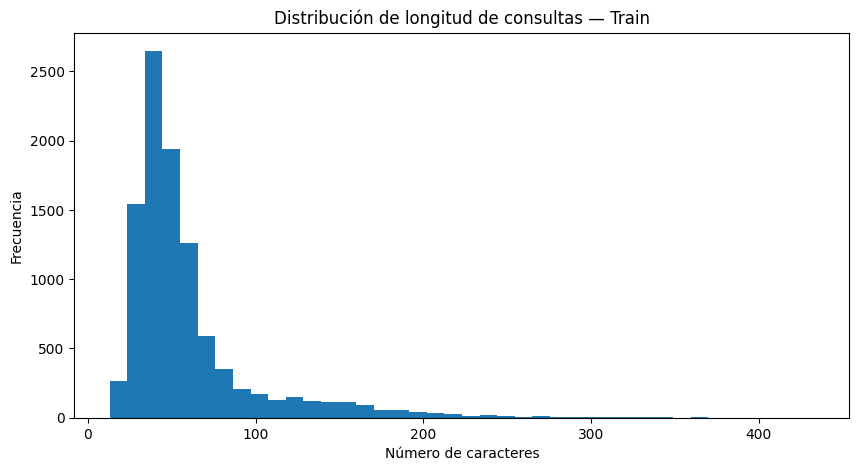

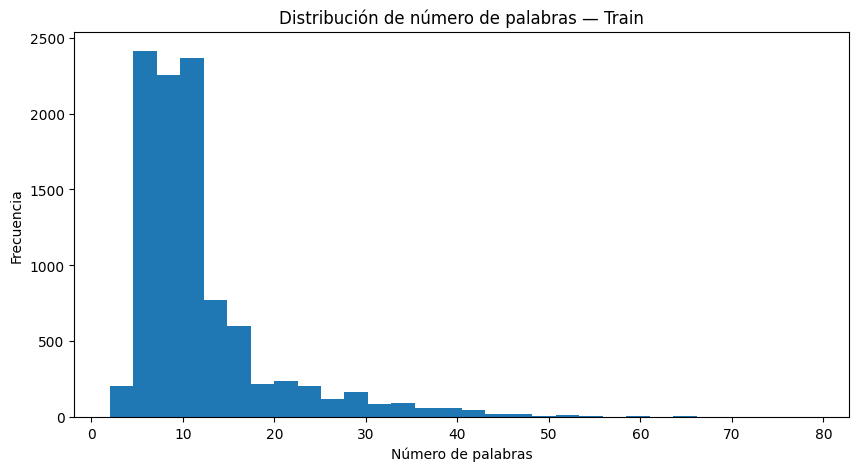

In [7]:
plt.figure(figsize=(10,5))
plt.hist(train_df["char_length"], bins=40)
plt.title("Distribución de longitud de consultas — Train")
plt.xlabel("Número de caracteres")
plt.ylabel("Frecuencia")
plt.show()

plt.figure(figsize=(10,5))
plt.hist(train_df["word_count"], bins=30)
plt.title("Distribución de número de palabras — Train")
plt.xlabel("Número de palabras")
plt.ylabel("Frecuencia")
plt.show()

## 1.4 Limpieza básica del texto

Se convierte a minúsculas, se eliminan caracteres especiales y números, y se eliminan *stopwords* en inglés.

> Esta limpieza se usa solo para el EDA léxico. Para DistilRoBERTa se conserva el texto original.

In [8]:
STOPWORDS = set(ENGLISH_STOP_WORDS)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [t for t in text.split() if t not in STOPWORDS and len(t) > 1]
    return " ".join(tokens)

train_df["clean_text"] = train_df["text"].apply(clean_text)
test_df["clean_text"] = test_df["text"].apply(clean_text)

display(train_df[["text", "clean_text"]].head(10))

,text,clean_text
0,I am still waiting on my card?,waiting card
1,What can I do if my card still hasn't arrived ...,card hasn arrived weeks
2,I have been waiting over a week. Is the card s...,waiting week card coming
3,Can I track my card while it is in the process...,track card process delivery
4,"How do I know if I will get my card, or if it ...",know card lost
5,When did you send me my new card?,did send new card
6,Do you have info about the card on delivery?,info card delivery
7,What do I do if I still have not received my n...,received new card
8,Does the package with my card have tracking?,does package card tracking
9,I ordered my card but it still isn't here,ordered card isn


## 1.5 Las 15 palabras más frecuentes

,palabra,frecuencia
0,card,2682
1,account,1352
2,money,1133
3,transfer,1084
4,payment,751
5,need,698
6,cash,691
7,exchange,549
8,charged,529
9,atm,482


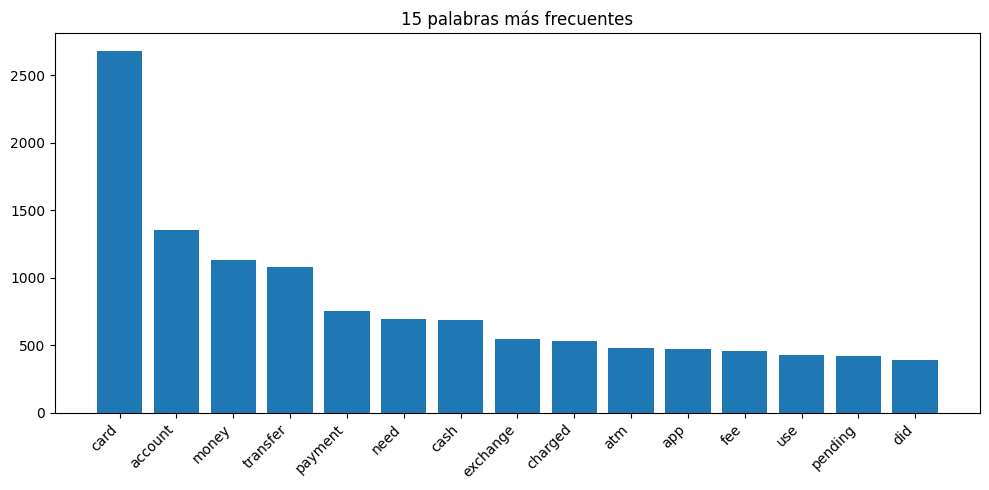

In [9]:
all_tokens = " ".join(train_df["clean_text"]).split()
word_freq = Counter(all_tokens)

top15_words = pd.DataFrame(word_freq.most_common(15), columns=["palabra", "frecuencia"])
display(top15_words)

plt.figure(figsize=(10,5))
plt.bar(top15_words["palabra"], top15_words["frecuencia"])
plt.title("15 palabras más frecuentes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 1.6 Los 10 bigramas y 10 trigramas más frecuentes

In [10]:
def top_ngrams(texts, ngram_range, top_n=10):
    vectorizer = CountVectorizer(ngram_range=ngram_range, min_df=2)
    matrix = vectorizer.fit_transform(texts)
    frequencies = np.asarray(matrix.sum(axis=0)).ravel()
    terms = np.asarray(vectorizer.get_feature_names_out())
    order = frequencies.argsort()[::-1][:top_n]
    return pd.DataFrame({"ngrama": terms[order], "frecuencia": frequencies[order]})

top10_bigrams = top_ngrams(train_df["clean_text"], (2,2), 10)
top10_trigrams = top_ngrams(train_df["clean_text"], (3,3), 10)

print("10 bigramas más frecuentes")
display(top10_bigrams)
print("\n10 trigramas más frecuentes")
display(top10_trigrams)

10 bigramas más frecuentes


,ngrama,frecuencia
0,exchange rate,293
1,new card,226
2,card payment,202
3,virtual card,181
4,cash withdrawal,165
5,money account,148
6,transfer money,118
7,long does,109
8,direct debit,102
9,extra fee,97



10 trigramas más frecuentes


,ngrama,frecuencia
0,disposable virtual card,63
1,exchange rate wrong,43
2,transfer money account,34
3,charged extra fee,33
4,direct debit payment,33
5,exchange rate applied,27
6,wrong exchange rate,26
7,couple days ago,24
8,order new card,24
9,disposable virtual cards,22


## 1.7 Nube de palabras

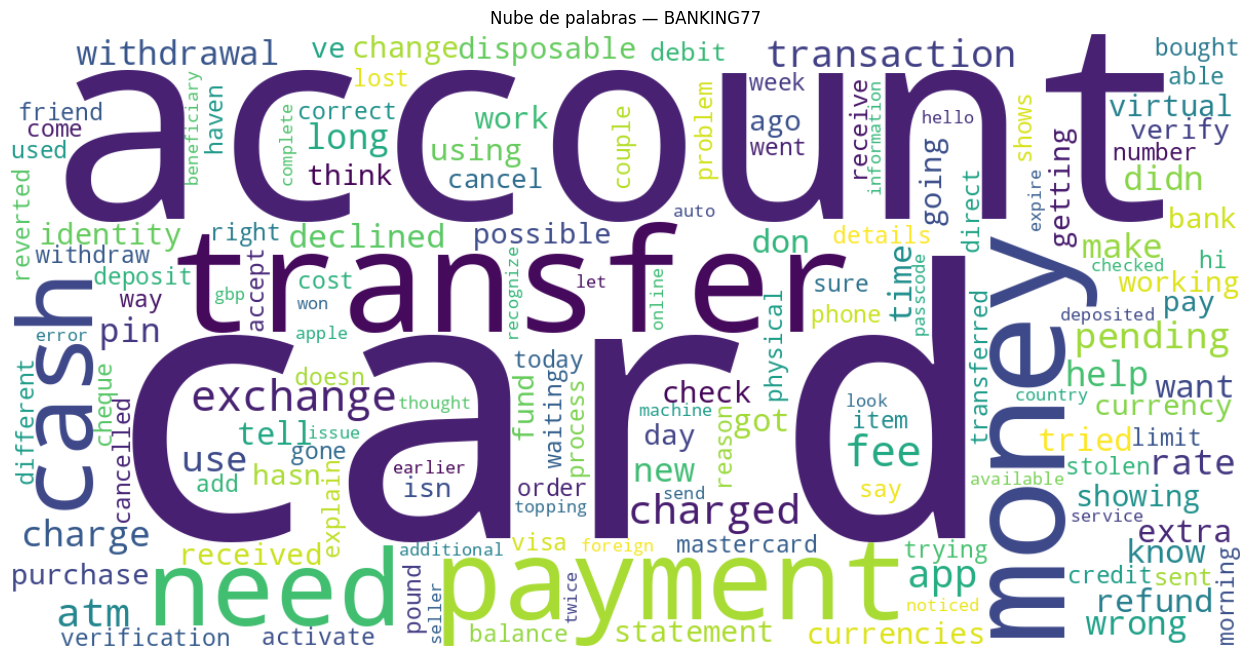

In [11]:
wc = WordCloud(
    width=1200, height=600, background_color="white",
    max_words=150, collocations=False, random_state=SEED
).generate(" ".join(train_df["clean_text"]))

plt.figure(figsize=(16,8))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Nube de palabras — BANKING77")
plt.show()

## 1.8 Verificar si el conjunto está balanceado

,métrica,valor
0,Número de clases,77.000000
1,Mínimo por clase,35.000000
2,Máximo por clase,187.000000
3,Media por clase,129.909091
4,Desviación estándar,32.942207
5,Razón máximo/mínimo,5.342857
6,Coeficiente de variación,0.253579


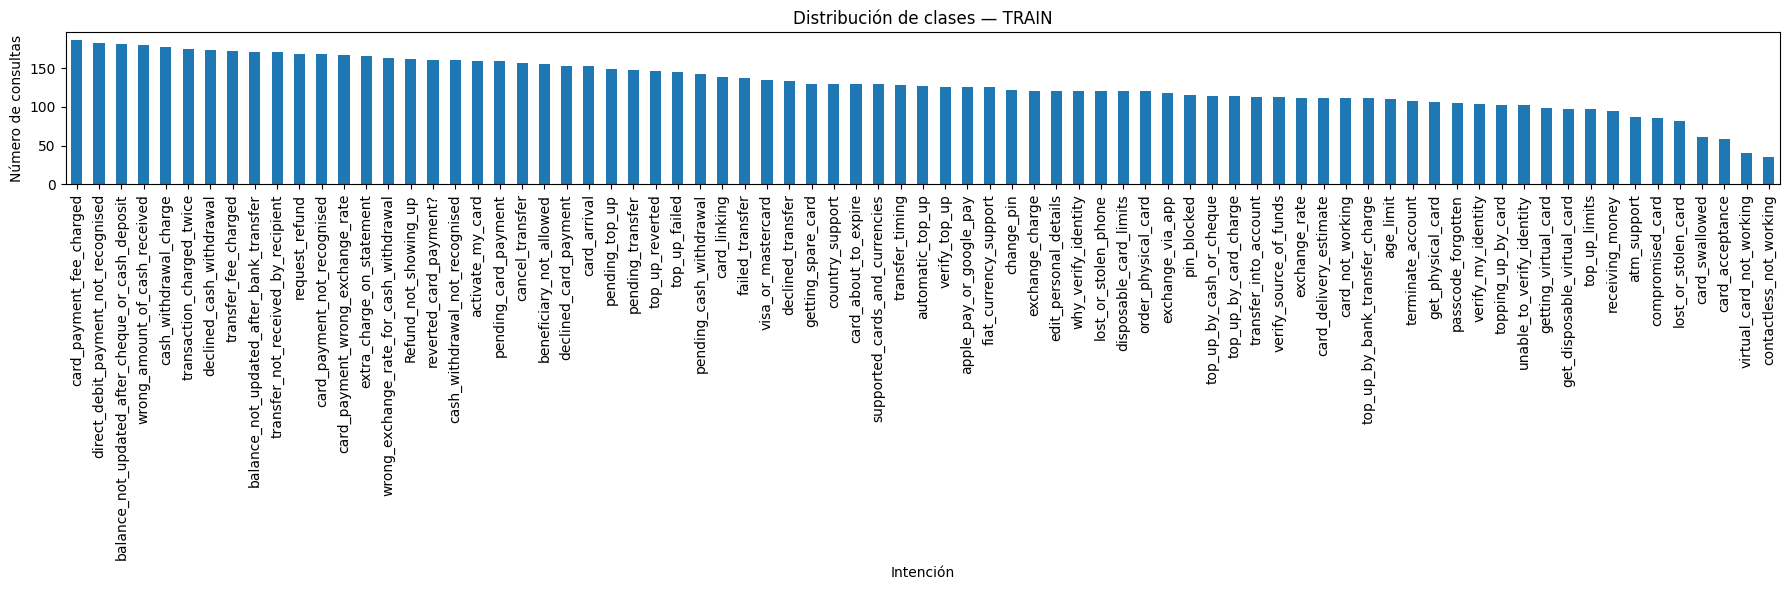

Conclusión: existe cierto desequilibrio (max/min=5.34, CV=0.254).


In [12]:
class_distribution = train_df["intent"].value_counts().sort_values(ascending=False)

balance_summary = pd.DataFrame({
    "métrica": [
        "Número de clases", "Mínimo por clase", "Máximo por clase",
        "Media por clase", "Desviación estándar",
        "Razón máximo/mínimo", "Coeficiente de variación"
    ],
    "valor": [
        class_distribution.size, class_distribution.min(),
        class_distribution.max(), class_distribution.mean(),
        class_distribution.std(),
        class_distribution.max()/class_distribution.min(),
        class_distribution.std()/class_distribution.mean()
    ]
})
display(balance_summary)

plt.figure(figsize=(18,6))
class_distribution.plot(kind="bar")
plt.title("Distribución de clases — TRAIN")
plt.xlabel("Intención")
plt.ylabel("Número de consultas")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

ratio = class_distribution.max()/class_distribution.min()
cv = class_distribution.std()/class_distribution.mean()

if ratio <= 1.5 and cv <= 0.20:
    print(f"Conclusión: conjunto relativamente balanceado (max/min={ratio:.2f}, CV={cv:.3f}).")
else:
    print(f"Conclusión: existe cierto desequilibrio (max/min={ratio:.2f}, CV={cv:.3f}).")

## 1.9 Conclusiones del análisis exploratorio

In [13]:
print("RESUMEN AUTOMÁTICO DEL EDA")
print("-"*60)
print(f"Train: {len(train_df):,} consultas")
print(f"Test : {len(test_df):,} consultas")
print(f"Clases: {num_labels}")
print(f"Longitud media: {train_df['char_length'].mean():.2f} caracteres")
print(f"Palabras medias: {train_df['word_count'].mean():.2f}")
print(f"Longitud mediana: {train_df['char_length'].median():.0f}")
print(f"Palabras mediana: {train_df['word_count'].median():.0f}")
print(f"Razón max/min de clases: {ratio:.2f}")
print(f"Coeficiente de variación: {cv:.3f}")
print("Top 15 palabras:", ", ".join(top15_words["palabra"].tolist()))

RESUMEN AUTOMÁTICO DEL EDA
------------------------------------------------------------
Train: 10,003 consultas
Test : 3,080 consultas
Clases: 77
Longitud media: 59.47 caracteres
Palabras medias: 11.95
Longitud mediana: 47
Palabras mediana: 10
Razón max/min de clases: 5.34
Coeficiente de variación: 0.254
Top 15 palabras: card, account, money, transfer, payment, need, cash, exchange, charged, atm, app, fee, use, pending, did


### RESUMEN AUTOMÁTICO DEL EDA
------------------------------------------------------------
Train: 10,003 consultas

Test : 3,080 consultas

Clases: 77

Longitud media: 59.47 caracteres

Palabras medias: 11.95

Longitud mediana: 47

Palabras mediana: 10

Razón max/min de clases: 5.34

Coeficiente de variación: 0.254

Top 15 palabras: card, account, money, transfer, payment, need, cash, exchange, charged, atm, app, fee, use, pending, did

# 2. Clasificación con Transformer (DistilRoBERTa)

## 2.1 Crear train/validation/test

In [14]:
split = dataset["train"].train_test_split(
    test_size=0.10, seed=SEED, stratify_by_column="label"
)
train_ds = split["train"]
val_ds = split["test"]
test_ds = dataset["test"]

if FAST_MODE:
    train_ds = train_ds.train_test_split(
        train_size=min(2500, len(train_ds)),
        seed=SEED, stratify_by_column="label"
    )["train"]
    val_ds = val_ds.train_test_split(
        train_size=min(700, len(val_ds)),
        seed=SEED, stratify_by_column="label"
    )["train"]

print("Train:", len(train_ds))
print("Validation:", len(val_ds))
print("Test:", len(test_ds))

Train: 9002
Validation: 1001
Test: 3080


## 2.2 Tokenización con el tokenizer de DistilRoBERTa

In [15]:
MODEL_NAME = "distilbert/distilroberta-base"
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_batch(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_train = train_ds.map(tokenize_batch, batched=True)
tokenized_val = val_ds.map(tokenize_batch, batched=True)
tokenized_test = test_ds.map(tokenize_batch, batched=True)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
print(tokenized_train[0])

config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Map:   0%|          | 0/9002 [00:00<?, ? examples/s]

Map:   0%|          | 0/1001 [00:00<?, ? examples/s]

Map:   0%|          | 0/3080 [00:00<?, ? examples/s]

{'text': 'I want to use auto top-up. Is there a limit?', 'label': 4, 'input_ids': [0, 100, 236, 7, 304, 4485, 299, 12, 658, 4, 1534, 89, 10, 3000, 116, 2], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


## 2.3 Modelo y fine-tuning

In [16]:
id2label = {i: label for i, label in enumerate(label_names)}
label2id = {label: i for i, label in enumerate(label_names)}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    acc = accuracy_score(labels, preds)
    p, r, f1, _ = precision_recall_fscore_support(
        labels, preds, average="macro", zero_division=0
    )
    _, _, f1w, _ = precision_recall_fscore_support(
        labels, preds, average="weighted", zero_division=0
    )
    return {
        "accuracy": acc,
        "precision_macro": p,
        "recall_macro": r,
        "f1_macro": f1,
        "f1_weighted": f1w,
    }

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: distilbert/distilroberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [17]:
epochs = 1 if FAST_MODE else 4

ta_params = inspect.signature(TrainingArguments.__init__).parameters

training_kwargs = dict(
    output_dir=str(OUTPUT_DIR / "distilroberta_banking77"),
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=epochs,
    weight_decay=0.01,
    save_strategy="epoch",
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    save_total_limit=2,
    report_to="none",
    fp16=torch.cuda.is_available(),
    seed=SEED,
)

if "eval_strategy" in ta_params:
    training_kwargs["eval_strategy"] = "epoch"
else:
    training_kwargs["evaluation_strategy"] = "epoch"

training_args = TrainingArguments(**training_kwargs)

trainer_kwargs = dict(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer_params = inspect.signature(Trainer.__init__).parameters
if "processing_class" in trainer_params:
    trainer_kwargs["processing_class"] = tokenizer
elif "tokenizer" in trainer_params:
    trainer_kwargs["tokenizer"] = tokenizer

trainer = Trainer(**trainer_kwargs)
print(training_args)

TrainingArguments(
accelerator_config={'split_batches': False, 'dispatch_batches': None, 'even_batches': True, 'use_seedable_sampler': True, 'non_blocking': False, 'gradient_accumulation_kwargs': None, 'use_configured_state': False},
adam_beta1=0.9,
adam_beta2=0.999,
adam_epsilon=1e-08,
auto_find_batch_size=False,
average_tokens_across_devices=True,
batch_eval_metrics=False,
bf16=False,
bf16_full_eval=False,
data_seed=None,
dataloader_drop_last=False,
dataloader_in_order=True,
dataloader_multiprocessing_context=None,
dataloader_num_workers=0,
dataloader_persistent_workers=False,
dataloader_pin_memory=True,
dataloader_prefetch_factor=None,
ddp_backend=None,
ddp_broadcast_buffers=None,
ddp_bucket_cap_mb=None,
ddp_find_unused_parameters=None,
ddp_static_graph=None,
ddp_timeout=1800,
debug=[],
deepspeed=None,
disable_tqdm=False,
do_eval=True,
do_predict=False,
do_train=False,
enable_jit_checkpoint=False,
eval_accumulation_steps=None,
eval_delay=0,
eval_do_concat_batches=True,
eval_on_start

In [18]:
train_result = trainer.train()
train_result

Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
1,1.773448,1.451251,0.784216,0.760056,0.749748,0.731433,0.761767
2,0.905644,0.762765,0.859141,0.867193,0.840289,0.839514,0.853189
3,0.607198,0.572854,0.878122,0.880221,0.866279,0.865652,0.874804
4,0.519844,0.519449,0.886114,0.886411,0.874490,0.874061,0.883391


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2252, training_loss=1.3178434778487915, metrics={'train_runtime': 167.1934, 'train_samples_per_second': 215.367, 'train_steps_per_second': 13.469, 'total_flos': 362983437353172.0, 'train_loss': 1.3178434778487915, 'epoch': 4.0})

## 2.4 Accuracy, matriz de confusión y reporte de métricas

In [19]:
test_output = trainer.predict(tokenized_test)
test_logits = test_output.predictions
y_true = np.asarray(test_output.label_ids)
y_pred = np.argmax(test_logits, axis=1)

exp_logits = np.exp(test_logits - np.max(test_logits, axis=1, keepdims=True))
probs = exp_logits / exp_logits.sum(axis=1, keepdims=True)
confidence = probs.max(axis=1)

test_metrics = compute_metrics((test_logits, y_true))
metrics_df = pd.DataFrame({"Métrica": list(test_metrics.keys()), "Valor": list(test_metrics.values())})
display(metrics_df)
metrics_df.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)

,Métrica,Valor
0,accuracy,0.895455
1,precision_macro,0.906894
2,recall_macro,0.895455
3,f1_macro,0.890864
4,f1_weighted,0.890864


In [20]:
report_dict = classification_report(
    y_true, y_pred,
    labels=list(range(num_labels)),
    target_names=label_names,
    output_dict=True,
    zero_division=0,
)
report_df = pd.DataFrame(report_dict).T
display(report_df.loc[label_names].sort_values("f1-score", ascending=False))
report_df.to_csv(OUTPUT_DIR / "classification_report.csv")

,precision,recall,f1-score,support
age_limit,1.000000,1.000,1.000000,40.0
edit_personal_details,1.000000,1.000,1.000000,40.0
verify_source_of_funds,0.975610,1.000,0.987654,40.0
passcode_forgotten,0.975610,1.000,0.987654,40.0
verify_top_up,0.975610,1.000,0.987654,40.0
...,...,...,...,...
getting_virtual_card,0.609375,0.975,0.750000,40.0
topping_up_by_card,0.731707,0.750,0.740741,40.0
get_disposable_virtual_card,0.611111,0.825,0.702128,40.0
why_verify_identity,0.894737,0.425,0.576271,40.0


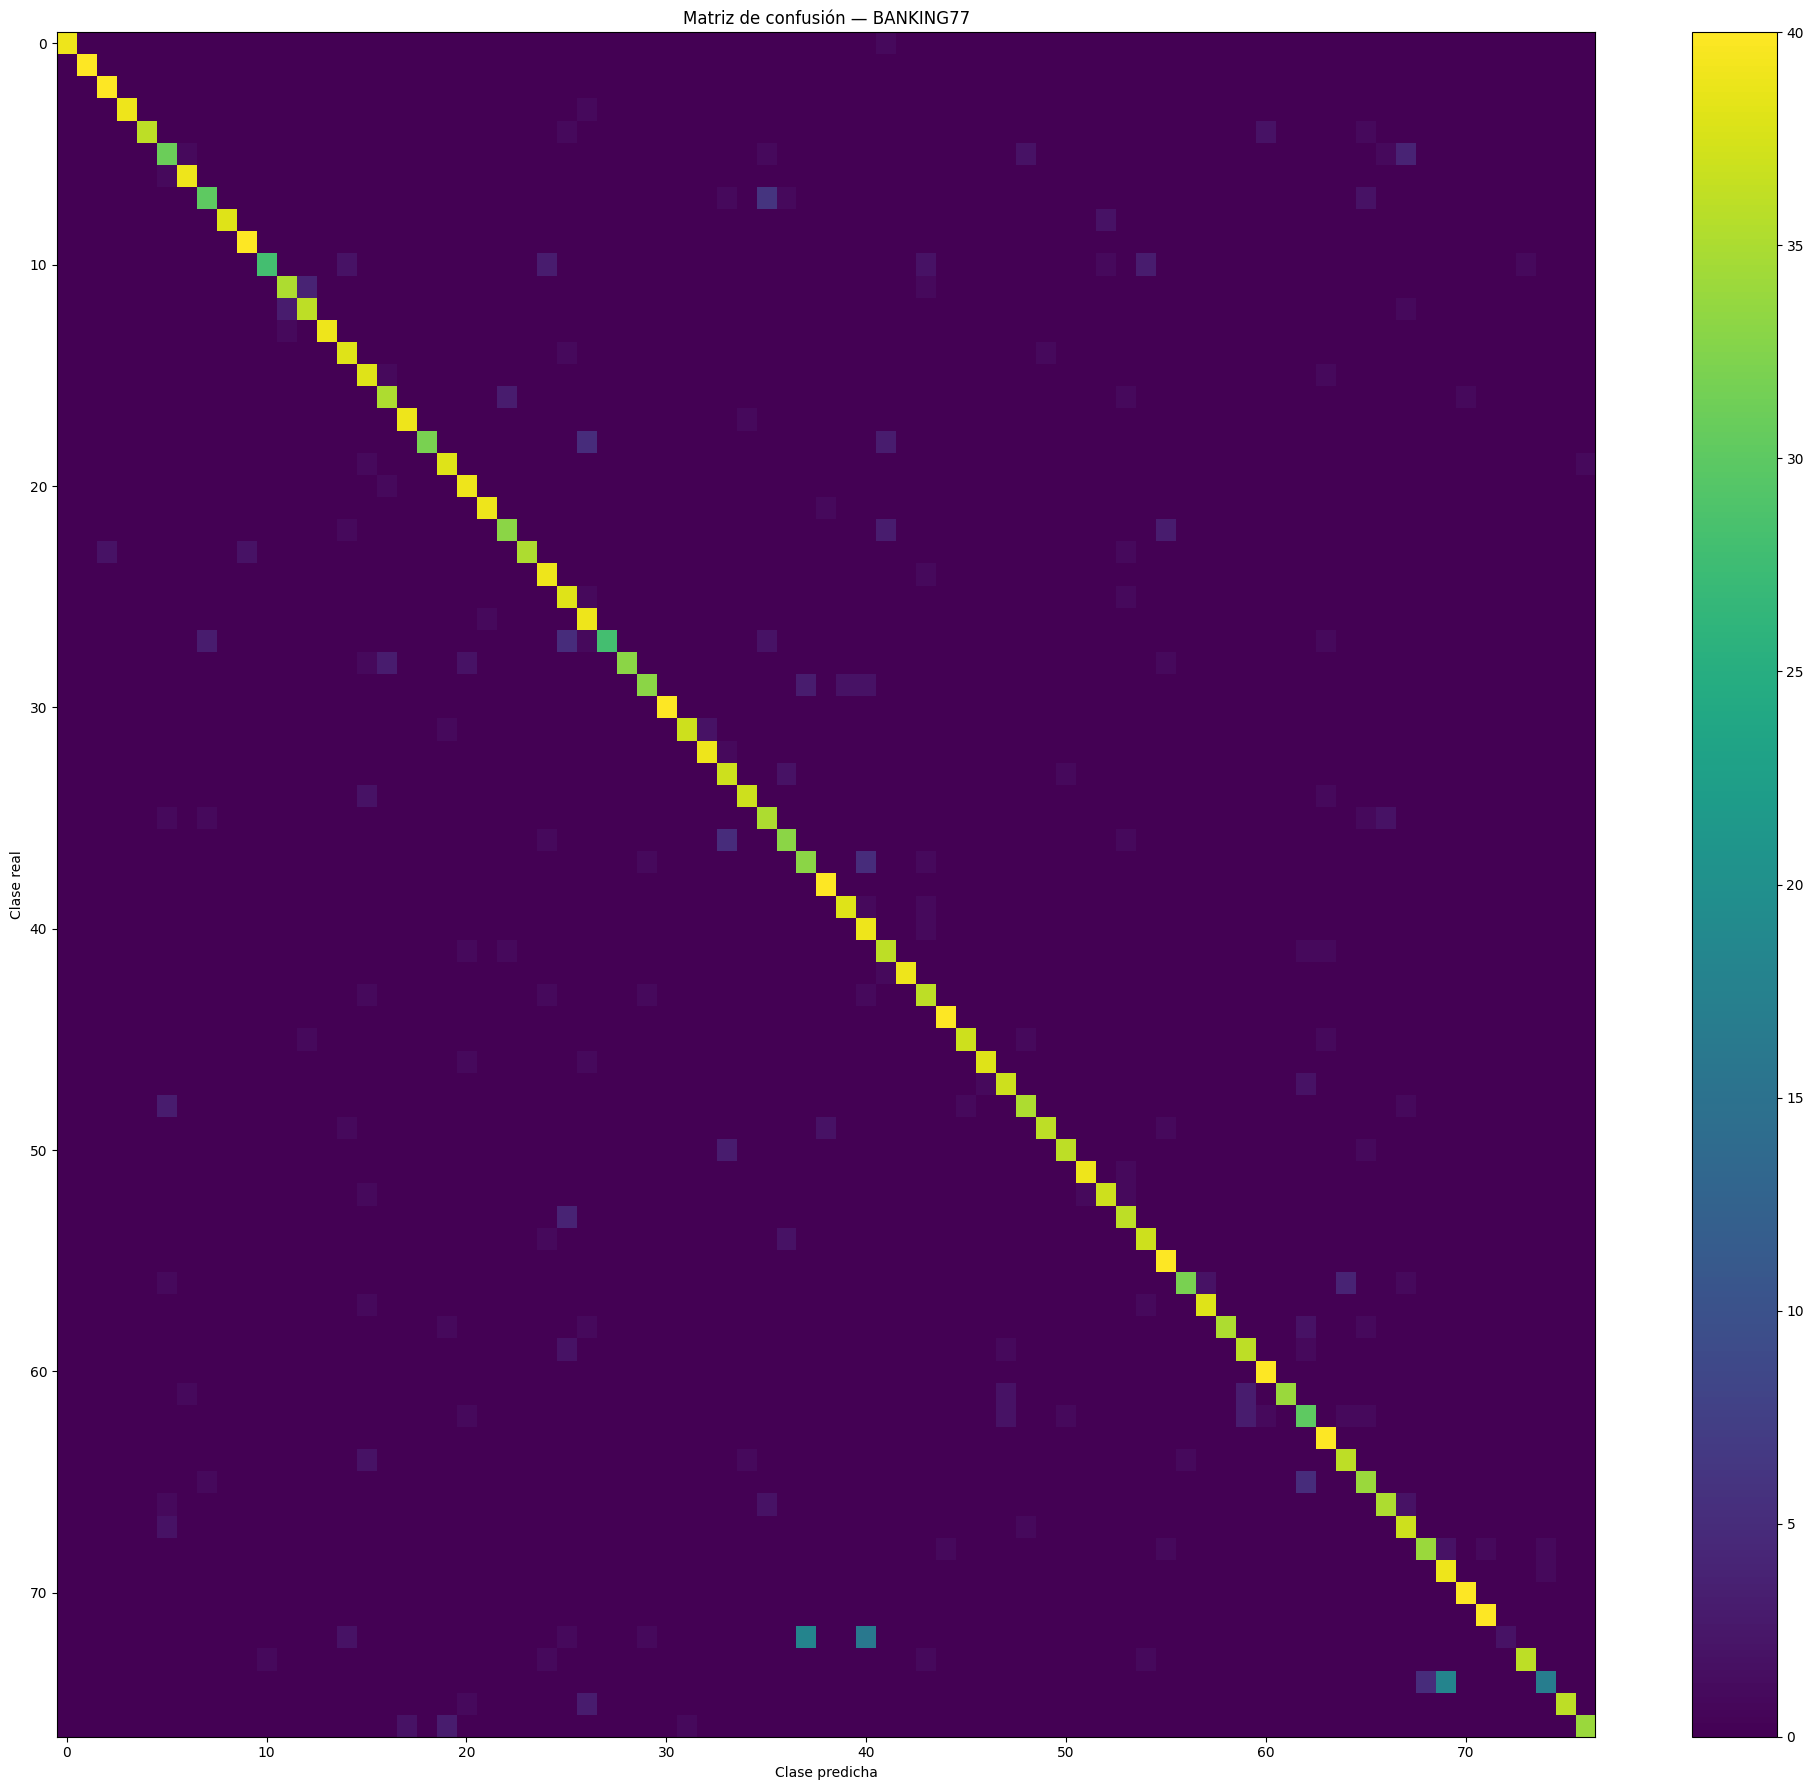

In [21]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(num_labels)))

plt.figure(figsize=(20,18))
plt.imshow(cm, interpolation="nearest", aspect="auto")
plt.title("Matriz de confusión — BANKING77")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.colorbar()
plt.tight_layout()
plt.show()

## 2.5  Tabla de errores

In [22]:
predictions_df = pd.DataFrame({
    "text": test_ds["text"],
    "true_id": y_true,
    "pred_id": y_pred,
    "true_label": [label_names[i] for i in y_true],
    "pred_label": [label_names[i] for i in y_pred],
    "confidence": confidence,
})
predictions_df["correct"] = predictions_df["true_id"] == predictions_df["pred_id"]

errors_df = (
    predictions_df[~predictions_df["correct"]]
    .copy()
    .sort_values("confidence", ascending=False)
    .reset_index(drop=True)
)

print("Predicciones:", len(predictions_df))
print("Aciertos:", predictions_df["correct"].sum())
print("Errores:", len(errors_df))
print(f"Accuracy: {predictions_df['correct'].mean():.4f}")
display(errors_df.head(20))

predictions_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
errors_df.to_csv(OUTPUT_DIR / "classification_errors.csv", index=False)

Predicciones: 3080
Aciertos: 2758
Errores: 322
Accuracy: 0.8955


,text,true_id,pred_id,true_label,pred_label,confidence,correct
0,I would like to know why my payment is still p...,48,45,pending_transfer,pending_card_payment,0.922121,False
1,"I was double charged, and the second charge is...",45,63,pending_card_payment,transaction_charged_twice,0.886725,False
2,Where do I find the exchange rate?,31,32,exchange_charge,exchange_rate,0.878494,False
3,Will declined funds I tried to withdraw be ret...,75,26,wrong_amount_of_cash_received,declined_cash_withdrawal,0.853957,False
4,whats your exchange rate,31,32,exchange_charge,exchange_rate,0.844306,False
5,How do I freeze my account?,22,55,compromised_card,terminate_account,0.842257,False
6,My cash withdrawal was partly declined,75,26,wrong_amount_of_cash_received,declined_cash_withdrawal,0.825820,False
7,Why did I get a fee?,19,15,cash_withdrawal_charge,card_payment_fee_charged,0.819244,False
8,Where can I view my PIN?,49,38,pin_blocked,get_physical_card,0.818850,False
9,My transfer is pending.,5,48,balance_not_updated_after_bank_transfer,pending_transfer,0.806218,False


## 2.6 Siete clases mejor clasificadas

In [23]:
per_class_report = report_df.loc[label_names].copy()

best7 = (
    per_class_report
    .sort_values(["f1-score", "precision", "recall"], ascending=False)
    .head(7)[["precision", "recall", "f1-score", "support"]]
)

display(best7)

,precision,recall,f1-score,support
age_limit,1.00000,1.000,1.000000,40.0
edit_personal_details,1.00000,1.000,1.000000,40.0
passcode_forgotten,0.97561,1.000,0.987654,40.0
verify_source_of_funds,0.97561,1.000,0.987654,40.0
verify_top_up,0.97561,1.000,0.987654,40.0
activate_my_card,1.00000,0.975,0.987342,40.0
atm_support,1.00000,0.975,0.987342,40.0


## 2.7 Siete clases con mayor número de errores

In [24]:
correct_by_class = np.diag(cm)
support_by_class = cm.sum(axis=1)
errors_by_class = support_by_class - correct_by_class

class_error_df = pd.DataFrame({
    "class_id": range(num_labels),
    "class": label_names,
    "support": support_by_class,
    "correct": correct_by_class,
    "errors": errors_by_class,
})
class_error_df["error_rate"] = class_error_df["errors"] / class_error_df["support"]

worst7_errors = (
    class_error_df
    .sort_values(["errors", "error_rate"], ascending=False)
    .head(7)
)

display(worst7_errors)

,class_id,class,support,correct,errors,error_rate
72,72,virtual_card_not_working,40,2,38,0.950
74,74,why_verify_identity,40,17,23,0.575
10,10,card_acceptance,40,28,12,0.300
27,27,declined_transfer,40,28,12,0.300
7,7,beneficiary_not_allowed,40,30,10,0.250
62,62,topping_up_by_card,40,30,10,0.250
5,5,balance_not_updated_after_bank_transfer,40,31,9,0.225


## 2.8 Confusiones y posibles causas del bajo desempeño

In [25]:
confusion_pairs = (
    errors_df.groupby(["true_label", "pred_label"])
    .size()
    .reset_index(name="n")
    .sort_values("n", ascending=False)
    .reset_index(drop=True)
)
display(confusion_pairs.head(20))
confusion_pairs.to_csv(OUTPUT_DIR / "confusion_pairs.csv", index=False)

,true_label,pred_label,n
0,why_verify_identity,verify_my_identity,18
1,virtual_card_not_working,get_disposable_virtual_card,18
2,virtual_card_not_working,getting_virtual_card,16
3,beneficiary_not_allowed,failed_transfer,6
4,card_swallowed,declined_cash_withdrawal,5
5,declined_transfer,declined_card_payment,5
6,get_disposable_virtual_card,getting_virtual_card,5
7,fiat_currency_support,exchange_via_app,5
8,transfer_into_account,topping_up_by_card,5
9,why_verify_identity,unable_to_verify_identity,5


In [26]:
analysis_rows = []

for true_label in worst7_errors["class"]:
    subset = errors_df[errors_df["true_label"] == true_label]
    if len(subset) == 0:
        continue
    vc = subset["pred_label"].value_counts()
    pred_label = vc.index[0]
    n = int(vc.iloc[0])
    examples = subset[subset["pred_label"] == pred_label]["text"].head(3).tolist()
    analysis_rows.append({
        "clase_problemática": true_label,
        "confusión_principal": pred_label,
        "n_confusiones": n,
        "ejemplos": " | ".join(examples),
    })

problematic_analysis = pd.DataFrame(analysis_rows)
display(problematic_analysis)

,clase_problemática,confusión_principal,n_confusiones,ejemplos
0,virtual_card_not_working,get_disposable_virtual_card,18,I cannot use my disposable virtual card. | Is ...
1,why_verify_identity,verify_my_identity,18,What is the purpose for the identity check | w...
2,card_acceptance,country_support,3,"I am traveling to Germany, Will I be able to u..."
3,declined_transfer,declined_card_payment,5,When I try and to buy something using my card ...
4,beneficiary_not_allowed,failed_transfer,6,The account transfer I was trying to do failed...
5,topping_up_by_card,top_up_failed,3,Cannot access my top up. | Why is my money gon...
6,balance_not_updated_after_bank_transfer,transfer_timing,4,How long does it take for an international tra...


### Posibles causas a discutir
- Solapamiento semántico entre intenciones.
- Consultas cortas o ambiguas.
- Estados muy próximos de una misma operación: *pending*, *failed*, *declined*, *reverted*.
- Clases del mismo producto: tarjeta, transferencia, retirada de efectivo, *top-up*.
- Falta de palabras explícitas que distingan una intención.
- Ejemplos fronterizos que podrían requerir contexto adicional.

## 2.9 Conclusiones del Transformer

In [27]:
print("CONCLUSIONES AUTOMÁTICAS — DISTILROBERTA")
print("-"*65)
print(f"Accuracy: {test_metrics['accuracy']:.4f}")
print(f"F1 macro: {test_metrics['f1_macro']:.4f}")
print("7 mejores clases:", ", ".join(best7.index.tolist()))
print("7 clases con más errores:", ", ".join(worst7_errors["class"].tolist()))

CONCLUSIONES AUTOMÁTICAS — DISTILROBERTA
-----------------------------------------------------------------
Accuracy: 0.8955
F1 macro: 0.8909
7 mejores clases: age_limit, edit_personal_details, passcode_forgotten, verify_source_of_funds, verify_top_up, activate_my_card, atm_support
7 clases con más errores: virtual_card_not_working, why_verify_identity, card_acceptance, declined_transfer, beneficiary_not_allowed, topping_up_by_card, balance_not_updated_after_bank_transfer


### DistilRoBERTa
DistilRoBERTa permite abordar BANKING77 como un problema de clasificación multiclase aprovechando representaciones contextuales preentrenadas. Las métricas globales describen el rendimiento general, mientras que el F1 por clase y la matriz de confusión muestran que el desempeño no es homogéneo entre las 77 intenciones. Las clases problemáticas suelen presentar solapamiento semántico o diferencias sutiles de estado, por lo que la accuracy debe complementarse con un análisis por clase y de errores concretos.

# 3. Prompt con Falcon-7B-Instruct

## 3.1 20 muestras mal clasificadas

La selección es reproducible. La clase real se conserva para evaluación, pero **no se entrega al LLM** durante la generación de la explicación.

In [28]:
if "errors_df" not in globals():
    errors_df = pd.read_csv(OUTPUT_DIR / "classification_errors.csv")

n_samples = min(20, len(errors_df))
falcon_samples = errors_df.sample(n=n_samples, random_state=SEED).reset_index(drop=True)
falcon_samples["sample_id"] = np.arange(1, len(falcon_samples)+1)

display(falcon_samples[["sample_id","text","true_label","pred_label","confidence"]])

,sample_id,text,true_label,pred_label,confidence
0,1,How would I use my money in a different country?,exchange_via_app,receiving_money,0.446818
1,2,How do I cancel my card? There are charges on ...,cash_withdrawal_not_recognised,card_payment_not_recognised,0.503637
2,3,My funding to my card didn't go through.,top_up_failed,declined_card_payment,0.394600
3,4,My transfer is pending.,balance_not_updated_after_bank_transfer,pending_transfer,0.806218
4,5,I was charged for something I didn't expect,transfer_fee_charged,card_payment_fee_charged,0.539951
5,6,Do I have to do an identity check?,why_verify_identity,verify_my_identity,0.520345
6,7,Double check your funds may be declined,declined_transfer,declined_cash_withdrawal,0.289749
7,8,Is it a good time to exchange?,exchange_rate,exchange_via_app,0.469788
8,9,help me with my transfer,failed_transfer,balance_not_updated_after_bank_transfer,0.336021
9,10,I followed the instructions to transfer money ...,topping_up_by_card,transfer_into_account,0.134622


## 3.2 Diseñar un prompt anti-alucinación

In [29]:
def build_falcon_prompt(text, predicted_label):
    readable_label = predicted_label.replace("_", " ")
    return f"""
You are explaining the output of a banking intent classifier.

Banking query:
"{text}"

Predicted intent:
"{readable_label}"

Explain why the query could have been interpreted as the predicted intent.

Rules:
- Use only information explicitly present in the query and the predicted intent name.
- Do not invent customer details, transaction details, amounts, dates, bank policies, causes, or outcomes.
- Do not propose another intent.
- Mention the words or meaning in the query that support the predicted intent.
- If there is not enough evidence, say exactly: "Insufficient evidence".
- Write a maximum of TWO short sentences.

Explanation:
""".strip()

In [30]:
r = falcon_samples.iloc[0]
print(build_falcon_prompt(r["text"], r["pred_label"]))

You are explaining the output of a banking intent classifier.

Banking query:
"How would I use my money in a different country?"

Predicted intent:
"receiving money"

Explain why the query could have been interpreted as the predicted intent.

Rules:
- Use only information explicitly present in the query and the predicted intent name.
- Do not invent customer details, transaction details, amounts, dates, bank policies, causes, or outcomes.
- Do not propose another intent.
- Mention the words or meaning in the query that support the predicted intent.
- If there is not enough evidence, say exactly: "Insufficient evidence".
- Write a maximum of TWO short sentences.

Explanation:


## 3.3 Liberar GPU antes de Falcon

En una Tesla T4 no conviene mantener DistilRoBERTa y Falcon-7B simultáneamente.

In [31]:
for var_name in [
    "trainer", "model", "test_output", "test_logits",
    "tokenized_train", "tokenized_val", "tokenized_test"
]:
    if var_name in globals():
        del globals()[var_name]

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()
    free, total = torch.cuda.mem_get_info()
    print(f"VRAM libre: {free/1024**3:.2f} GB")
    print(f"VRAM total: {total/1024**3:.2f} GB")

VRAM libre: 14.06 GB
VRAM total: 14.56 GB


Si quedan muy pocos GB libres, reinicia la sesión y vuelve a ejecutar únicamente:
1. instalación/importaciones;
2. definición de `OUTPUT_DIR`;
3. carga de `classification_errors.csv`;
4. celdas de Falcon.

## 3.4 Cargar Falcon-7B-Instruct en 4 bits

In [32]:
FALCON_MODEL_NAME = "tiiuae/falcon-7b-instruct"

falcon_tokenizer = None
falcon_model = None

if RUN_FALCON and torch.cuda.is_available():
    falcon_tokenizer = AutoTokenizer.from_pretrained(FALCON_MODEL_NAME)

    if falcon_tokenizer.pad_token is None:
        falcon_tokenizer.pad_token = falcon_tokenizer.eos_token

    quant_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=torch.float16,
    )

    falcon_model = AutoModelForCausalLM.from_pretrained(
        FALCON_MODEL_NAME,
        quantization_config=quant_config,
        device_map={"": 0},
        low_cpu_mem_usage=True,
    )

    falcon_model.eval()
    print("Falcon cargado correctamente.")

    free, total = torch.cuda.mem_get_info()
    print(f"VRAM usada: {(total-free)/1024**3:.2f} GB")
    print(f"VRAM libre: {free/1024**3:.2f} GB")
else:
    print("Falcon no cargado: revisa RUN_FALCON y CUDA.")

config.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.13k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.73M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/281 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/17.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

[transformers] You are loading your model using eetq but no linear modules were found in your model. Please double check your model architecture, or submit an issue on github if you think this is a bug.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/117 [00:00<?, ?B/s]

Falcon cargado correctamente.
VRAM usada: 14.23 GB
VRAM libre: 0.34 GB


## 3.5 Función de generación

In [33]:
def generate_explanation(
    prompt, temperature=0.2, max_new_tokens=70,
    top_p=0.9, seed=SEED
):
    if falcon_model is None:
        raise RuntimeError("Falcon no está cargado.")

    set_seed(seed)

    inputs = falcon_tokenizer(
        prompt, return_tensors="pt",
        truncation=True, max_length=1024
    )
    inputs = {k: v.to("cuda:0") for k, v in inputs.items()}

    do_sample = temperature > 0

    kwargs = dict(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=do_sample,
        repetition_penalty=1.05,
        pad_token_id=falcon_tokenizer.eos_token_id,
        eos_token_id=falcon_tokenizer.eos_token_id,
    )

    if do_sample:
        kwargs["temperature"] = temperature
        kwargs["top_p"] = top_p

    with torch.no_grad():
        output_ids = falcon_model.generate(**kwargs)

    generated = output_ids[0, inputs["input_ids"].shape[1]:]
    return falcon_tokenizer.decode(generated, skip_special_tokens=True).strip()

## 3.6 Calibrar temperatura y longitud

In [34]:
calibration_configs = [
    {"name":"determinista_corta", "temperature":0.0, "max_new_tokens":45},
    {"name":"baja_controlada", "temperature":0.2, "max_new_tokens":70},
    {"name":"alta_larga", "temperature":0.7, "max_new_tokens":110},
]

calibration_rows = []

if falcon_model is not None:
    for _, row in falcon_samples.head(3).iterrows():
        prompt = build_falcon_prompt(row["text"], row["pred_label"])

        for cfg in calibration_configs:
            explanation = generate_explanation(
                prompt,
                temperature=cfg["temperature"],
                max_new_tokens=cfg["max_new_tokens"],
            )
            sentences = [
                s for s in re.split(r"[.!?]+", explanation) if s.strip()
            ]
            calibration_rows.append({
                "sample_id": row["sample_id"],
                "pred_label": row["pred_label"],
                "config": cfg["name"],
                "temperature": cfg["temperature"],
                "max_new_tokens": cfg["max_new_tokens"],
                "explanation": explanation,
                "n_words": len(explanation.split()),
                "n_sentences_approx": len(sentences),
            })

calibration_df = pd.DataFrame(calibration_rows)
display(calibration_df)

,sample_id,pred_label,config,temperature,max_new_tokens,explanation,n_words,n_sentences_approx
0,1,receiving_money,determinista_corta,0.0,45,"The query ""How would I use my money in a diffe...",36,3
1,1,receiving_money,baja_controlada,0.2,70,"The query ""How would I use my money in a diffe...",59,4
2,1,receiving_money,alta_larga,0.7,110,"The query ""How would I use my money in a diffe...",55,3
3,2,card_payment_not_recognised,determinista_corta,0.0,45,"- The query contains the word ""card"", which is...",34,2
4,2,card_payment_not_recognised,baja_controlada,0.2,70,"- The query contains the word ""card"" which mat...",56,4
5,2,card_payment_not_recognised,alta_larga,0.7,110,- The customer is inquiring about canceling a ...,38,2
6,3,declined_card_payment,determinista_corta,0.0,45,"The query contains the word ""funding,"" which i...",35,3
7,3,declined_card_payment,baja_controlada,0.2,70,"The query contains the word ""funding,"" which i...",53,3
8,3,declined_card_payment,alta_larga,0.7,110,"The query contains a single word (""funding"") t...",50,3


### Configuración elegida
Se propone `temperature=0.2`, `max_new_tokens=70` y `top_p=0.9`: temperatura baja para reducir variabilidad y respuesta corta para limitar información no solicitada.

In [35]:
BEST_TEMPERATURE = 0.2
BEST_MAX_NEW_TOKENS = 70
BEST_TOP_P = 0.9

## 3.7 Solicitar al LLM una justificación de las 20 clasificaciones incorrectas

In [36]:
falcon_results = []

if falcon_model is not None:
    for _, row in falcon_samples.iterrows():
        prompt = build_falcon_prompt(row["text"], row["pred_label"])
        explanation = generate_explanation(
            prompt,
            temperature=BEST_TEMPERATURE,
            max_new_tokens=BEST_MAX_NEW_TOKENS,
            top_p=BEST_TOP_P,
        )
        falcon_results.append({
            "sample_id": row["sample_id"],
            "text": row["text"],
            "true_label": row["true_label"],
            "pred_label": row["pred_label"],
            "confidence": row["confidence"],
            "explanation": explanation,
        })

falcon_results_df = pd.DataFrame(falcon_results)
display(falcon_results_df)

falcon_results_df.to_csv(
    OUTPUT_DIR / "falcon_20_misclassified_explanations.csv",
    index=False,
)

,sample_id,text,true_label,pred_label,confidence,explanation
0,1,How would I use my money in a different country?,exchange_via_app,receiving_money,0.446818,"The query ""How would I use my money in a diffe..."
1,2,How do I cancel my card? There are charges on ...,cash_withdrawal_not_recognised,card_payment_not_recognised,0.503637,"- The query contains the word ""card"" which mat..."
2,3,My funding to my card didn't go through.,top_up_failed,declined_card_payment,0.394600,"The query contains the word ""funding,"" which i..."
3,4,My transfer is pending.,balance_not_updated_after_bank_transfer,pending_transfer,0.806218,"The banking query ""My transfer is pending."" ca..."
4,5,I was charged for something I didn't expect,transfer_fee_charged,card_payment_fee_charged,0.539951,"The query contains the word ""charged"", which i..."
5,6,Do I have to do an identity check?,why_verify_identity,verify_my_identity,0.520345,"The banking query ""Do I have to do an identity..."
6,7,Double check your funds may be declined,declined_transfer,declined_cash_withdrawal,0.289749,"- The query contains the word ""double"", which ..."
7,8,Is it a good time to exchange?,exchange_rate,exchange_via_app,0.469788,"The query ""Is it a good time to exchange?"" can..."
8,9,help me with my transfer,failed_transfer,balance_not_updated_after_bank_transfer,0.336021,"The query ""help me with my transfer"" can be in..."
9,10,I followed the instructions to transfer money ...,topping_up_by_card,transfer_into_account,0.134622,"The query contains the word ""transfer"" which m..."


## 3.8 Analizar y listar las razones proporcionadas por el LLM

In [37]:
if len(falcon_results_df) > 0:
    for _, row in falcon_results_df.iterrows():
        print("="*90)
        print(f"Muestra {row['sample_id']}")
        print("Consulta:", row["text"])
        print("Clase real:", row["true_label"])
        print("Clase predicha:", row["pred_label"])
        print("Razón Falcon:", row["explanation"])
        print()

Muestra 1
Consulta: How would I use my money in a different country?
Clase real: exchange_via_app
Clase predicha: receiving_money
Razón Falcon: The query "How would I use my money in a different country?" can be interpreted as the predicted intent "receiving money" because it explicitly mentions the act of receiving money. The customer is asking about the process of transferring money to another country, which is a common banking service provided by banks. The customer is likely seeking information on

Muestra 2
Consulta: How do I cancel my card? There are charges on my account that I didn't make.
Clase real: cash_withdrawal_not_recognised
Clase predicha: card_payment_not_recognised
Razón Falcon: - The query contains the word "card" which matches the name of the predicted intent.
- The query also contains the word "payment" which matches the name of the predicted intent.
- The query does not contain any other information that could be used to interpret it as a different intent.
- There

## 3.9 Control básico de alucinaciones e incumplimiento

In [38]:
def evaluate_falcon_row(row):
    query = str(row["text"]).lower()
    explanation = str(row["explanation"]).strip()
    expl_lower = explanation.lower()

    query_numbers = set(re.findall(r"\d+(?:\.\d+)?", query))
    explanation_numbers = set(re.findall(r"\d+(?:\.\d+)?", expl_lower))
    sentence_count = len([
        s for s in re.split(r"[.!?]+", explanation) if s.strip()
    ])

    return pd.Series({
        "invented_number_flag": bool(explanation_numbers - query_numbers),
        "word_count": len(explanation.split()),
        "sentence_count_approx": sentence_count,
        "over_two_sentences_flag": sentence_count > 2,
        "insufficient_evidence": "insufficient evidence" in expl_lower,
    })

if len(falcon_results_df) > 0:
    falcon_eval = pd.concat(
        [falcon_results_df, falcon_results_df.apply(evaluate_falcon_row, axis=1)],
        axis=1,
    )
    display(falcon_eval[[
        "sample_id","pred_label","invented_number_flag",
        "word_count","sentence_count_approx",
        "over_two_sentences_flag","insufficient_evidence"
    ]])
    falcon_eval.to_csv(OUTPUT_DIR / "falcon_evaluation.csv", index=False)

,sample_id,pred_label,invented_number_flag,word_count,sentence_count_approx,over_two_sentences_flag,insufficient_evidence
0,1,receiving_money,False,59,4,True,False
1,2,card_payment_not_recognised,False,56,4,True,False
2,3,declined_card_payment,False,53,3,True,False
3,4,pending_transfer,False,46,3,True,False
4,5,card_payment_fee_charged,False,49,2,False,False
5,6,verify_my_identity,False,50,3,True,False
6,7,declined_cash_withdrawal,False,47,5,True,False
7,8,exchange_via_app,False,56,4,True,False
8,9,balance_not_updated_after_bank_transfer,False,55,2,False,False
9,10,transfer_into_account,False,45,2,False,False


## 3.10 Plantilla de evaluación manual

In [39]:
if len(falcon_results_df) > 0:
    manual_eval = falcon_results_df.copy()
    manual_eval["coherence_1_5"] = np.nan
    manual_eval["fidelity_1_5"] = np.nan
    manual_eval["relevance_1_5"] = np.nan
    manual_eval["clarity_1_5"] = np.nan
    manual_eval["hallucination_1_5"] = np.nan
    manual_eval["comentario_manual"] = ""
    display(manual_eval)
    manual_eval.to_csv(OUTPUT_DIR / "falcon_manual_evaluation.csv", index=False)

,sample_id,text,true_label,pred_label,confidence,explanation,coherence_1_5,fidelity_1_5,relevance_1_5,clarity_1_5,hallucination_1_5,comentario_manual
0,1,How would I use my money in a different country?,exchange_via_app,receiving_money,0.446818,"The query ""How would I use my money in a diffe...",NaN,NaN,NaN,NaN,NaN,
1,2,How do I cancel my card? There are charges on ...,cash_withdrawal_not_recognised,card_payment_not_recognised,0.503637,"- The query contains the word ""card"" which mat...",NaN,NaN,NaN,NaN,NaN,
2,3,My funding to my card didn't go through.,top_up_failed,declined_card_payment,0.394600,"The query contains the word ""funding,"" which i...",NaN,NaN,NaN,NaN,NaN,
3,4,My transfer is pending.,balance_not_updated_after_bank_transfer,pending_transfer,0.806218,"The banking query ""My transfer is pending."" ca...",NaN,NaN,NaN,NaN,NaN,
4,5,I was charged for something I didn't expect,transfer_fee_charged,card_payment_fee_charged,0.539951,"The query contains the word ""charged"", which i...",NaN,NaN,NaN,NaN,NaN,
5,6,Do I have to do an identity check?,why_verify_identity,verify_my_identity,0.520345,"The banking query ""Do I have to do an identity...",NaN,NaN,NaN,NaN,NaN,
6,7,Double check your funds may be declined,declined_transfer,declined_cash_withdrawal,0.289749,"- The query contains the word ""double"", which ...",NaN,NaN,NaN,NaN,NaN,
7,8,Is it a good time to exchange?,exchange_rate,exchange_via_app,0.469788,"The query ""Is it a good time to exchange?"" can...",NaN,NaN,NaN,NaN,NaN,
8,9,help me with my transfer,failed_transfer,balance_not_updated_after_bank_transfer,0.336021,"The query ""help me with my transfer"" can be in...",NaN,NaN,NaN,NaN,NaN,
9,10,I followed the instructions to transfer money ...,topping_up_by_card,transfer_into_account,0.134622,"The query contains the word ""transfer"" which m...",NaN,NaN,NaN,NaN,NaN,


## 3.11 Conclusiones sobre el uso del LLM

Falcon-7B-Instruct puede utilizarse como herramienta de explicación **post-hoc** para convertir una predicción del clasificador en una justificación legible. En las muestras incorrectas, el LLM ayuda a identificar palabras y significados que pueden haber favorecido la clase predicha. Sin embargo, la explicación no representa el mecanismo interno real de DistilRoBERTa, sino una interpretación semántica plausible.

La calibración del prompt es esencial. Una temperatura baja, una longitud máxima reducida y reglas explícitas disminuyen respuestas especulativas, aunque no eliminan completamente las alucinaciones. Por ello, las explicaciones deben considerarse apoyo para el análisis de errores y no evidencia causal de por qué el Transformer tomó una decisión.

# 4. Bibliografia

- Casanueva, I., Temčinas, T., Gerz, D., Henderson, M., & Vulić, I. (2020). Efficient intent detection with dual sentence encoders. In Proceedings of the 2nd Workshop on Natural Language Processing for Conversational AI (pp. 38–45). Association for Computational Linguistics. https://doi.org/10.18653/v1/2020.nlp4convai-1.5

- Liu, Y., Ott, M., Goyal, N., Du, J., Joshi, M., Chen, D., Levy, O., Lewis, M., Zettlemoyer, L., & Stoyanov, V. (2019). RoBERTa: A robustly optimized BERT pretraining approach. arXiv. https://doi.org/10.48550/arXiv.1907.11692

- Penedo, G., Malartic, Q., Hesslow, D., Cojocaru, R., Cappelli, A., Alobeidli, H., Pannier, B., Almazrouei, E., & Launay, J. (2023). The RefinedWeb dataset for Falcon LLM: Outperforming curated corpora with web data, and web data only. arXiv. https://doi.org/10.48550/arXiv.2306.01116

- Sanh, V., Debut, L., Chaumond, J., & Wolf, T. (2019). DistilBERT, a distilled version of BERT: Smaller, faster, cheaper and lighter. arXiv. https://doi.org/10.48550/arXiv.1910.01108 arXiv